In [1]:
import idx2numpy
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

In [2]:
X_train = idx2numpy.convert_from_file('mnist/train-images.idx3-ubyte')
y_train = idx2numpy.convert_from_file('mnist/train-labels.idx1-ubyte')

X_test  = idx2numpy.convert_from_file('mnist/t10k-images.idx3-ubyte')
y_test  = idx2numpy.convert_from_file('mnist/t10k-labels.idx1-ubyte')

In [3]:
# размер изображения
image_width = X_train[0].shape[0]
image_height = X_train[0].shape[1]

# выходов

num_outputs = 10

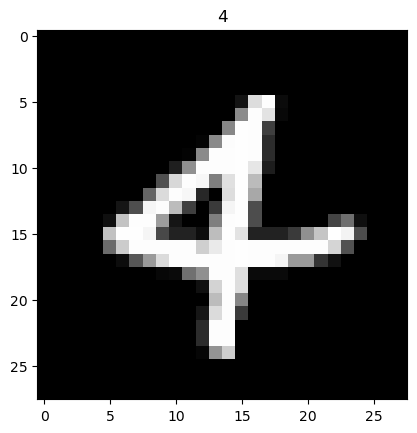

In [4]:
idx = 150
plt.imshow(X_train[idx], "grey")
plt.title(f'{y_train[idx]}')
pass

## формулы backpropogation

Кросс энтропия:
$$ L = -\sum^{10}_{c = 1} y_c \log \hat y_c $$

$y_c$ - **c** компонента one-hot вектора правильного ответа, $\hat y_c$ - вероятность класса **c** (после softmax)

$\hat y$ = softmax($z^{(2)}$)

$z^{(2)}$ - линейная комбинация выходов скрытого слоя: $z^{(2)}_l$ = $\displaystyle\sum^{s}_{i = 1} \omega_{i, l}^{(2)}R_i + b_l^{(2)}$ 

$R_i$ = $ReLU(z^{(1)}_i)$

$z^{(1)}$ - линейная комбинация входов: $z^{(1)}_l$ = $\displaystyle\sum^{n}_{i = 1} \omega_{i, l}^{(1)}x_i + b_l^{(1)}$

### Формулы для скрытого слоя:

$$\displaystyle\frac{\partial L}{\partial \omega_{i,j}} = \sum_{p, s} \frac{\partial L}{\partial \hat y_{p}} \frac{\partial \hat y_{p}}{\partial z^{(2)}_s} \frac{\partial z^{(2)}_s}{\partial \omega_{i,j}^{(2)}}$$ - основная формула

$\displaystyle\frac{\partial L}{\partial \hat y_{p}} = -\sum^{10}_{c = 1} y_c \frac{\delta_{cp}}{\hat y_c} = -\frac{y_p}{\hat y_p}$


$
\displaystyle
\frac{\partial \hat y_{p}}{\partial z^{(2)}_s}
= \frac{e^{z^{(2)}_p}\delta_{sp}}{\displaystyle\sum^{10}_{c=1} e^{z^{(2)}_c}}
- \frac{e^{z^{(2)}_p} e^{z^{(2)}_s}}{\left(\displaystyle\sum^{10}_{c=1} e^{z^{(2)}_c}\right)^2}
= \delta_{sp}\hat y_{p} - \hat y_{p}\hat y_{s} = \hat y_{p}(\delta_{sp} - \hat y_{s})
$

$\displaystyle\frac{\partial z^{(2)}_s}{\partial \omega_{i,j}^{(2)}} = \frac{\partial (\displaystyle\sum_{i = 1} \omega_{i, l}^{(2)}R_i + b_l^{(2)})}{\partial \omega_{i,j}^{(2)}} = \displaystyle \sum^{s}_{t = 1} \delta_{ti} \delta_{js}R_t = \delta_{js}R_i$

$=> \displaystyle\frac{\partial L}{\partial \omega_{i,j}^{(2)}} = -\sum_{p, s} \frac{y_p}{\hat y_p} \hat y_{p}(\delta_{sp} - \hat y_{s}) \delta_{js}R_i = \sum_{p} y_p (\delta_{jp} - \hat y_{j})R_i = -R_i(y_{j} - \hat y_{j})$ - итоговая формула для весов выходного слоя

Для смещения

$$\displaystyle\frac{\partial L}{\partial b_i^{(2)}} = \sum_{p, s} \frac{\partial L}{\partial \hat y_{p}} \frac{\partial \hat y_{p}}{\partial z^{(2)}_s} \frac{\partial z^{(2)}_s}{\partial b_i^{(2)}}$$

$\displaystyle\frac{\partial z^{(2)}_s}{\partial b_i^{(2)}} = \delta_{is}$

$\displaystyle\frac{\partial L}{\partial b_i^{(2)}} = -(y_{j} - \hat y_{j})$ - итоговая формула для смещений второго слоя

### для первого слоя 

$$\displaystyle\frac{\partial L}{\partial \omega_{k,l}^{(1)}} = \sum_{p, s, i, j} \frac{\partial L}{\partial \hat y_{p}} \frac{\partial \hat y_{p}}{\partial z^{(2)}_s} \frac{\partial z^{(2)}_s}{\partial R_i} \frac{\partial R_i}{\partial z^{(1)}_j} \frac{\partial z^{(1)}_j}{\partial \omega_{k,l}^{(1)}}$$ - основная формула для скрытого слоя

$\displaystyle\frac{\partial z^{(2)}_s}{\partial R_i} = \omega_{i,s}^{(2)}$

$\displaystyle\frac{\partial R_i}{\partial z^{(1)}_j} = \frac{\partial ReLU(z^{(1)}_i)}{\partial z^{(1)}_j} = \delta_{ij}M[z^{(1)}_i]$

$M[z^{(1)}_i]$ - маска. 1 если $z^{(1)}_i$ > 0, 0 иначе

$\displaystyle\frac{\partial z^{(1)}_j}{\partial \omega_{k,l}^{(1)}} = \frac{\partial (\displaystyle\sum^{n}_{i = 1} \omega_{i, j}^{(1)}x_i + b_j^{(1)})}{\partial \omega_{k,l}^{(1)}} = \displaystyle \sum^{n}_{t = 1} \delta_{ki} \delta_{jl}x_i = \delta_{jl}x_k$

$=> \displaystyle\frac{\partial L}{\partial \omega_{k,l}^{(1)}} = -\sum_{p, s, i, j} \frac{y_p}{\hat y_p} \hat y_{p}(\delta_{sp} - \hat y_{s}) \omega_{i,s}^{(2)} \delta_{js}M[z^{(1)}_i] \delta_{jl}x_k = -M[z^{(1)}_l]x_k\sum_{s} \omega_{l,s}^{(2)}(y_{s} - \hat y_{s})$ -  итоговая формула для весов скрытого слоя

для смещений

$$\displaystyle\frac{\partial L}{\partial b_m^{(1)}} = \sum_{p, s, i, j} \frac{\partial L}{\partial \hat y_{p}} \frac{\partial \hat y_{p}}{\partial z^{(2)}_s} \frac{\partial z^{(2)}_s}{\partial R_i} \frac{\partial R_i}{\partial z^{(1)}_j} \frac{\partial z^{(1)}_j}{\partial b_m^{(1)}}$$

$\displaystyle \frac{\partial L}{\partial b_m^{(1)}} = -\sum_{p, s, i, j} \frac{y_p}{\hat y_p} \hat y_{p}(\delta_{sp} - \hat y_{s}) \omega_{i,s}^{(2)} \delta_{js}M[z^{(1)}_i] \delta_{jm} = -M[z^{(1)}_m]\sum_{s} \omega_{m,s}^{(2)}(y_{s} - \hat y_{s})$ - итоговая формула для смещений скрытого слоя

## Итоговые формулы

- $\displaystyle\frac{\partial L}{\partial \omega_{i,j}^{(2)}} = R_i(\hat y_{j} - y_{j}), j = 1...10, i = 1...s$
- $\displaystyle\frac{\partial L}{\partial b_i^{(2)}} = \hat y_{j} - y_{j}, i = 1...10$
- $\displaystyle\frac{\partial L}{\partial \omega_{k,l}^{(1)}} = M[z^{(1)}_l]x_k\sum^{10}_{j} \omega_{l,j}^{(2)}(\hat y_{j} - y_{j}), l = 1...s, k = 1...n$
- $\displaystyle \frac{\partial L}{\partial b_m^{(1)}} = M[z^{(1)}_m]\sum^{10}_{j} \omega_{m,j}^{(2)}(\hat y_{j} - y_{j}), m = 1...s$

In [76]:
def cross_entropy(y_true: np.array, y_prob: np.array):
    true_index = y_true.argmax() # индекс макс элемента (единицы)
    return -np.log(y_prob[true_index])

def cross_entropy_batch(y_true, y_prob, eps=1e-12):
    p_true = (y_true * y_prob).sum(axis=1) # поэлементное умножение, останется только вероятность верного класса и нули, 
                                           # все суммируем получаем только вероятность нужного класса
    p_true = np.clip(p_true, eps, 1.0) # если 0 или больше 1
    return -np.mean(np.log(p_true))

def RelU(x):
    return np.maximum(0, x)

def softmax(x):
    x = x - x.max(axis=-1, keepdims=True)
    e = np.exp(x)
    return e / e.sum(axis=-1, keepdims=True)

def forward(params, input_flatten):
    W1, b1, W2, b2 = params

    # вход - скрытый слой
    input_first_layer = input_flatten @ W1
    Z1 = input_first_layer + b1
    R = RelU(Z1)
    
    # скрытый сой - выход
    output = R @ W2
    Z2 = output + b2
    
    probabilities = softmax(Z2)

    # выход - вектор вероятностей
    return probabilities

# y_labels целые метки НЕ onehot
def calc_accuracy(X, y_labels, params):
    W1, b1, W2, b2 = params
    
    input_first_layer = X @ W1
    Z1 = input_first_layer + b1
    R = RelU(Z1)
    
    output = R @ W2
    Z2 = output + b2
    
    labels = softmax(Z2).argmax(axis = 1)
    return np.mean(y_labels == labels)

# тест на первом изображении

In [10]:
image_experiment = X_train[0]
label = y_train[0]

In [11]:
X_train_flatten = X_train.reshape(X_train.shape[0], -1) / 255.0
y_train_one_hot = np.eye(10)[y_train]

X_test_flatten = X_test.reshape(X_test.shape[0], -1) / 255.0
y_test_one_hot = np.eye(10)[y_test]

In [12]:
# перемешивание
idx_train = np.random.permutation(len(X_train_flatten))

In [69]:
X_train_flatten.shape

(60000, 784)

# backprop

In [13]:
s = 300

learning_rate = 0.1

batch_size = 128

epochs = 3

100%|███████████████████████████████████████████████████████████████████████████████| 469/469 [00:03<00:00, 155.41it/s]


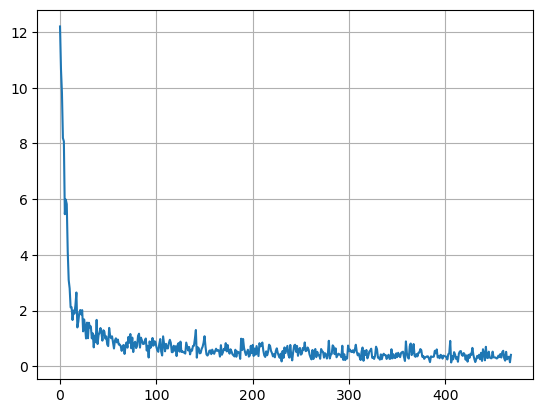

In [38]:
omega_hidden = np.random.uniform(low=-0.5, high=0.5, size=(image_width*image_height, s)) #np.random.normal(size=(image_width*image_height, s))
bias_hidden = np.random.uniform(low=-0.5, high=0.5, size=(s)) #np.random.normal(size=(s))

omega_out = np.random.uniform(low=-0.5, high=0.5, size=(s, num_outputs)) #np.random.normal(size=(s, num_outputs))
bias_out = np.random.uniform(low=-0.5, high=0.5, size=(num_outputs)) #np.random.normal(size=(num_outputs))

params = (omega_hidden, bias_hidden, omega_out, bias_out)

W1, b1, W2, b2 = params
idx_train = np.random.permutation(len(X_train_flatten))
loss_array = []

for start_idx in tqdm(range(0, len(X_train_flatten), batch_size)):
    batch_idx = idx_train[start_idx : start_idx + batch_size]

    X_batch = X_train_flatten[batch_idx]
    y_batch = y_train_one_hot[batch_idx]

    B = len(X_batch) # последний батч
    
    input_first_layer = X_batch @ W1
    Z1 = input_first_layer + b1
    R = RelU(Z1)
    
    # скрытый сой - выход
    output = R @ W2
    Z2 = output + b2

    probabilities = softmax(Z2)
    
    loss = cross_entropy_batch(y_batch, np.array(probabilities))
    loss_array.append(loss)
    
    # back
    delta_y = probabilities - y_batch
    
    dLdw2 = R.T @ delta_y
    dLdb2 = delta_y.sum(axis=0)
    Mask = (Z1>0).astype(int)
    mask_and_multiply = np.multiply(Mask, delta_y @ W2.T)
    dLdw1 = X_batch.T @ mask_and_multiply
    dLdb1 = mask_and_multiply.sum(axis=0)

    dLdw2_mean = dLdw2 / B
    dLdb2_mean = dLdb2 / B
    dLdw1_mean = dLdw1 / B
    dLdb1_mean = dLdb1 / B

    W2 = W2 - learning_rate*dLdw2_mean
    b2 = b2 - learning_rate*dLdb2_mean
    W1 = W1 - learning_rate*dLdw1_mean
    b1 = b1 - learning_rate*dLdb1_mean

plt.plot(loss_array)
plt.grid()

# по эпохам

In [83]:
s = 300

learning_rate = 0.1

batch_size = 128

epochs = 20

In [84]:
omega_hidden = np.random.uniform(low=-0.5, high=0.5, size=(image_width*image_height, s))
bias_hidden = np.random.uniform(low=-0.5, high=0.5, size=(s))

omega_out = np.random.uniform(low=-0.5, high=0.5, size=(s, num_outputs))
bias_out = np.random.uniform(low=-0.5, high=0.5, size=(num_outputs))

params = (omega_hidden, bias_hidden, omega_out, bias_out)

W1, b1, W2, b2 = params

loss_list = []
train_accuracy_list = []
test_accuracy_list = []
for epoch in range(epochs):
    print("epoch", epoch + 1)
    idx_train = np.random.permutation(len(X_train_flatten))
    
    for start_idx in tqdm(range(0, len(X_train_flatten), batch_size)):
        batch_idx = idx_train[start_idx : start_idx + batch_size]
    
        X_batch = X_train_flatten[batch_idx]
        y_batch = y_train_one_hot[batch_idx]
    
        B = len(X_batch) # последний батч
        
        input_first_layer = X_batch @ W1
        Z1 = input_first_layer + b1
        R = RelU(Z1)
        
        # скрытый сой - выход
        output = R @ W2
        Z2 = output + b2
    
        probabilities = softmax(Z2)
    
        loss = cross_entropy_batch(y_batch, probabilities)
        loss_list.append(loss)
        
        # back
        delta_y = probabilities - y_batch
        
        dLdw2 = R.T @ delta_y
        dLdb2 = delta_y.sum(axis=0)
        Mask = (Z1>0).astype(int)
        mask_and_multiply = np.multiply(Mask, delta_y @ W2.T)
        dLdw1 = X_batch.T @ mask_and_multiply
        dLdb1 = mask_and_multiply.sum(axis=0)
    
        dLdw2_mean = dLdw2 / B
        dLdb2_mean = dLdb2 / B
        dLdw1_mean = dLdw1 / B
        dLdb1_mean = dLdb1 / B
    
        W2 = W2 - learning_rate*dLdw2_mean
        b2 = b2 - learning_rate*dLdb2_mean
        W1 = W1 - learning_rate*dLdw1_mean
        b1 = b1 - learning_rate*dLdb1_mean

    train_accuracy = calc_accuracy(X_train_flatten, y_train, (W1, b1, W2, b2))
    test_accuracy = calc_accuracy(X_test_flatten, y_test, (W1, b1, W2, b2))
    
    train_accuracy_list.append(train_accuracy)
    test_accuracy_list.append(test_accuracy)
    
    print("Accuracy train:", train_accuracy)
    print("Accuracy test:", test_accuracy)


epoch 0


100%|███████████████████████████████████████████████████████████████████████████████| 469/469 [00:02<00:00, 167.05it/s]


Accuracy train: 0.9129833333333334
Accuracy test: 0.9117
epoch 1


100%|███████████████████████████████████████████████████████████████████████████████| 469/469 [00:03<00:00, 155.66it/s]


Accuracy train: 0.9376166666666667
Accuracy test: 0.9302
epoch 2


100%|███████████████████████████████████████████████████████████████████████████████| 469/469 [00:03<00:00, 155.18it/s]


... (31 outputs left out)

100%|███████████████████████████████████████████████████████████████████████████████| 469/469 [00:02<00:00, 157.24it/s]


Accuracy train: 0.9889
Accuracy test: 0.9623
epoch 19


100%|███████████████████████████████████████████████████████████████████████████████| 469/469 [00:03<00:00, 155.65it/s]


Accuracy train: 0.99005
Accuracy test: 0.9638


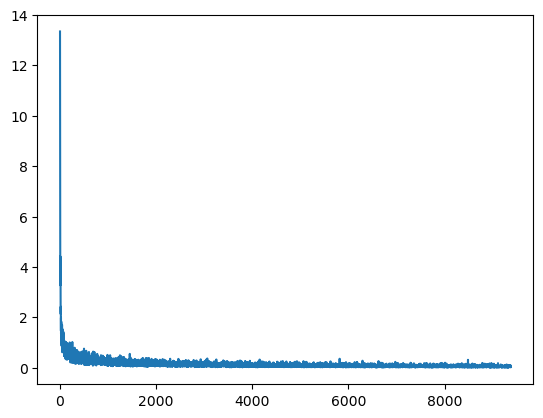

In [88]:
plt.plot(loss_list[:])


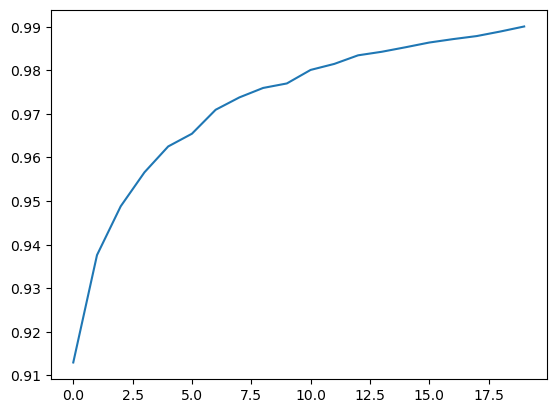

In [89]:
plt.plot(train_accuracy_list[:])


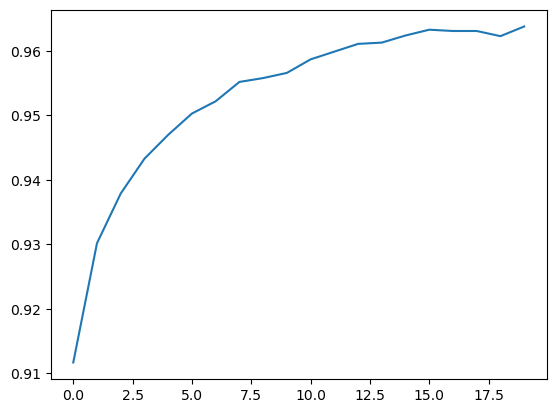

In [90]:
plt.plot(test_accuracy_list[:])


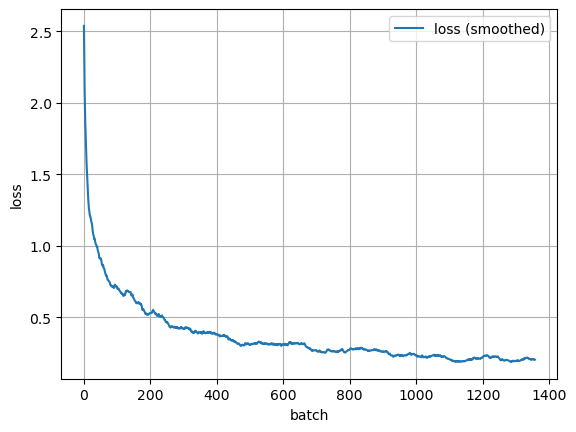

In [91]:
def smooth(x, k=50):
    return np.convolve(x, np.ones(k)/k, mode='valid')
plt.plot(smooth(loss_array), label='loss (smoothed)')
plt.xlabel('batch')
plt.ylabel('loss')
plt.legend()
plt.grid()
plt.show()

# попытка улучшить результат с помощью начальных весов

In [115]:
s = 300

learning_rate = 0.1

batch_size = 128

epochs = 20

In [116]:
rng = np.random.default_rng(42)

omega_hidden = rng.normal(
    loc=0.0,
    scale=np.sqrt(2.0 / (image_width * image_height)),
    size=(image_width * image_height, s)
)
bias_hidden = np.zeros(s)

omega_out = rng.normal(
    loc=0.0,
    scale=np.sqrt(2.0 / s),
    size=(s, num_outputs)
)
bias_out = np.zeros(num_outputs)

params = (omega_hidden, bias_hidden, omega_out, bias_out)

W1, b1, W2, b2 = params

loss_list = []
train_accuracy_list = []
test_accuracy_list = []
for epoch in range(epochs):
        
    print("epoch", epoch + 1)
    idx_train = np.random.permutation(len(X_train_flatten))
    
    for start_idx in tqdm(range(0, len(X_train_flatten), batch_size)):
        batch_idx = idx_train[start_idx : start_idx + batch_size]
    
        X_batch = X_train_flatten[batch_idx]
        y_batch = y_train_one_hot[batch_idx]
    
        B = len(X_batch) # последний батч
        
        input_first_layer = X_batch @ W1
        Z1 = input_first_layer + b1
        R = RelU(Z1)
        
        # скрытый сой - выход
        output = R @ W2
        Z2 = output + b2
    
        probabilities = softmax(Z2)
    
        loss = cross_entropy_batch(y_batch, probabilities)
        loss_list.append(loss)
        
        # back
        delta_y = probabilities - y_batch
        
        dLdw2 = R.T @ delta_y
        dLdb2 = delta_y.sum(axis=0)
        Mask = (Z1>0).astype(int)
        mask_and_multiply = np.multiply(Mask, delta_y @ W2.T)
        dLdw1 = X_batch.T @ mask_and_multiply
        dLdb1 = mask_and_multiply.sum(axis=0)
    
        dLdw2_mean = dLdw2 / B
        dLdb2_mean = dLdb2 / B
        dLdw1_mean = dLdw1 / B
        dLdb1_mean = dLdb1 / B
    
        W2 = W2 - learning_rate*dLdw2_mean
        b2 = b2 - learning_rate*dLdb2_mean
        W1 = W1 - learning_rate*dLdw1_mean
        b1 = b1 - learning_rate*dLdb1_mean

    train_accuracy = calc_accuracy(X_train_flatten, y_train, (W1, b1, W2, b2))
    test_accuracy = calc_accuracy(X_test_flatten, y_test, (W1, b1, W2, b2))
    
    train_accuracy_list.append(train_accuracy)
    test_accuracy_list.append(test_accuracy)
    
    print("Accuracy train:", train_accuracy)
    print("Accuracy test:", test_accuracy)


epoch 1


100%|███████████████████████████████████████████████████████████████████████████████| 469/469 [00:02<00:00, 157.05it/s]


Accuracy train: 0.9233666666666667
Accuracy test: 0.9266
epoch 2


100%|███████████████████████████████████████████████████████████████████████████████| 469/469 [00:02<00:00, 158.54it/s]


Accuracy train: 0.9402833333333334
Accuracy test: 0.9413
epoch 3


100%|███████████████████████████████████████████████████████████████████████████████| 469/469 [00:02<00:00, 159.67it/s]


... (31 outputs left out)

100%|███████████████████████████████████████████████████████████████████████████████| 469/469 [00:03<00:00, 155.63it/s]


Accuracy train: 0.9892166666666666
Accuracy test: 0.9788
epoch 20


100%|███████████████████████████████████████████████████████████████████████████████| 469/469 [00:03<00:00, 154.89it/s]


Accuracy train: 0.991
Accuracy test: 0.9792


# улучшить результат за счет lr

In [121]:
s = 300

learning_rate = 0.13

batch_size = 128

epochs = 20

In [122]:
rng = np.random.default_rng(42)

omega_hidden = rng.normal(
    loc=0.0,
    scale=np.sqrt(2.0 / (image_width * image_height)),
    size=(image_width * image_height, s)
)
bias_hidden = np.zeros(s)

omega_out = rng.normal(
    loc=0.0,
    scale=np.sqrt(2.0 / s),
    size=(s, num_outputs)
)
bias_out = np.zeros(num_outputs)

params = (omega_hidden, bias_hidden, omega_out, bias_out)

W1, b1, W2, b2 = params

loss_list = []
train_accuracy_list = []
test_accuracy_list = []
for epoch in range(epochs):
        
    print("epoch", epoch + 1)
    idx_train = np.random.permutation(len(X_train_flatten))
    
    for start_idx in range(0, len(X_train_flatten), batch_size):
        batch_idx = idx_train[start_idx : start_idx + batch_size]
    
        X_batch = X_train_flatten[batch_idx]
        y_batch = y_train_one_hot[batch_idx]
    
        B = len(X_batch) # последний батч
        
        input_first_layer = X_batch @ W1
        Z1 = input_first_layer + b1
        R = RelU(Z1)
        
        # скрытый сой - выход
        output = R @ W2
        Z2 = output + b2
    
        probabilities = softmax(Z2)
    
        loss = cross_entropy_batch(y_batch, probabilities)
        loss_list.append(loss)
        
        # back
        delta_y = probabilities - y_batch
        
        dLdw2 = R.T @ delta_y
        dLdb2 = delta_y.sum(axis=0)
        Mask = (Z1>0).astype(int)
        mask_and_multiply = np.multiply(Mask, delta_y @ W2.T)
        dLdw1 = X_batch.T @ mask_and_multiply
        dLdb1 = mask_and_multiply.sum(axis=0)
    
        dLdw2_mean = dLdw2 / B
        dLdb2_mean = dLdb2 / B
        dLdw1_mean = dLdw1 / B
        dLdb1_mean = dLdb1 / B
    
        W2 = W2 - learning_rate*dLdw2_mean
        b2 = b2 - learning_rate*dLdb2_mean
        W1 = W1 - learning_rate*dLdw1_mean
        b1 = b1 - learning_rate*dLdb1_mean

    train_accuracy = calc_accuracy(X_train_flatten, y_train, (W1, b1, W2, b2))
    test_accuracy = calc_accuracy(X_test_flatten, y_test, (W1, b1, W2, b2))
    
    train_accuracy_list.append(train_accuracy)
    test_accuracy_list.append(test_accuracy)
    
    print("Accuracy train:", train_accuracy)
    print("Accuracy test:", test_accuracy)


epoch 1
Accuracy train: 0.92915
Accuracy test: 0.9286
epoch 2
Accuracy train: 0.9468
Accuracy test: 0.9453
epoch 3
Accuracy train: 0.9575333333333333
Accuracy test: 0.9547
epoch 4
Accuracy train: 0.9651333333333333
Accuracy test: 0.9597
epoch 5
Accuracy train: 0.9699833333333333
Accuracy test: 0.9651
epoch 6
Accuracy train: 0.9744666666666667
Accuracy test: 0.9676
epoch 7
Accuracy train: 0.9773333333333334
Accuracy test: 0.9698
epoch 8
Accuracy train: 0.9798833333333333
Accuracy test: 0.9723
epoch 9
Accuracy train: 0.9819833333333333
Accuracy test: 0.9744
epoch 10
Accuracy train: 0.9823333333333333
Accuracy test: 0.9737
epoch 11
Accuracy train: 0.9843666666666666
Accuracy test: 0.9757
epoch 12
Accuracy train: 0.9872
Accuracy test: 0.9775
epoch 13
Accuracy train: 0.9882833333333333
Accuracy test: 0.9775
epoch 14
Accuracy train: 0.9894
Accuracy test: 0.9788
epoch 15
Accuracy train: 0.9904666666666667
Accuracy test: 0.9792
epoch 16
Accuracy train: 0.9913666666666666
Accuracy test: 0.9793


# momentum

In [131]:
s = 300

learning_rate = 0.13

batch_size = 128

epochs = 20

In [132]:
rng = np.random.default_rng(42)

omega_hidden = rng.normal(
    loc=0.0,
    scale=np.sqrt(2.0 / (image_width * image_height)),
    size=(image_width * image_height, s)
)
bias_hidden = np.zeros(s)

omega_out = rng.normal(
    loc=0.0,
    scale=np.sqrt(2.0 / s),
    size=(s, num_outputs)
)
bias_out = np.zeros(num_outputs)

params = (omega_hidden, bias_hidden, omega_out, bias_out)

W1, b1, W2, b2 = params

vW1 = np.zeros_like(W1)
vb1 = np.zeros_like(b1)
vW2 = np.zeros_like(W2)
vb2 = np.zeros_like(b2)

beta = 0.90

loss_list = []
train_accuracy_list = []
test_accuracy_list = []
for epoch in range(epochs):
    if epoch == 10:
        learning_rate = 0.01
    if epoch == 15:
        learning_rate = 0.001
        
    print("epoch", epoch + 1)
    idx_train = np.random.permutation(len(X_train_flatten))
    
    for start_idx in range(0, len(X_train_flatten), batch_size):
        batch_idx = idx_train[start_idx : start_idx + batch_size]
    
        X_batch = X_train_flatten[batch_idx]
        y_batch = y_train_one_hot[batch_idx]
    
        B = len(X_batch) # последний батч
        
        input_first_layer = X_batch @ W1
        Z1 = input_first_layer + b1
        R = RelU(Z1)
        
        # скрытый сой - выход
        output = R @ W2
        Z2 = output + b2
    
        probabilities = softmax(Z2)
    
        loss = cross_entropy_batch(y_batch, probabilities)
        loss_list.append(loss)
        
        # back
        delta_y = probabilities - y_batch
        
        dLdw2 = R.T @ delta_y
        dLdb2 = delta_y.sum(axis=0)
        Mask = (Z1>0).astype(int)
        mask_and_multiply = np.multiply(Mask, delta_y @ W2.T)
        dLdw1 = X_batch.T @ mask_and_multiply
        dLdb1 = mask_and_multiply.sum(axis=0)
    
        dLdw2_mean = dLdw2 / B
        dLdb2_mean = dLdb2 / B
        dLdw1_mean = dLdw1 / B
        dLdb1_mean = dLdb1 / B

        vW2 = beta * vW2 + dLdw2_mean
        vb2 = beta * vb2 + dLdb2_mean
        vW1 = beta * vW1 + dLdw1_mean
        vb1 = beta * vb1 + dLdb1_mean
        
        W2 = W2 - learning_rate * vW2
        b2 = b2 - learning_rate * vb2
        W1 = W1 - learning_rate * vW1
        b1 = b1 - learning_rate * vb1

    train_accuracy = calc_accuracy(X_train_flatten, y_train, (W1, b1, W2, b2))
    test_accuracy = calc_accuracy(X_test_flatten, y_test, (W1, b1, W2, b2))
    
    train_accuracy_list.append(train_accuracy)
    test_accuracy_list.append(test_accuracy)
    
    print("Accuracy train:", train_accuracy)
    print("Accuracy test:", test_accuracy)


epoch 1
Accuracy train: 0.9712
Accuracy test: 0.9669
epoch 2
Accuracy train: 0.9809333333333333
Accuracy test: 0.9716
epoch 3
Accuracy train: 0.9861166666666666
Accuracy test: 0.9759
epoch 4
Accuracy train: 0.9911333333333333
Accuracy test: 0.9771
epoch 5
Accuracy train: 0.9925
Accuracy test: 0.978
epoch 6
Accuracy train: 0.9963833333333333
Accuracy test: 0.98
epoch 7
Accuracy train: 0.9966833333333334
Accuracy test: 0.98
epoch 8
Accuracy train: 0.9975
Accuracy test: 0.9797
epoch 9
Accuracy train: 0.9991666666666666
Accuracy test: 0.9823
epoch 10
Accuracy train: 0.99955
Accuracy test: 0.9822
epoch 11
Accuracy train: 0.9999
Accuracy test: 0.9833
epoch 12
Accuracy train: 0.9999333333333333
Accuracy test: 0.9836
epoch 13
Accuracy train: 0.9999833333333333
Accuracy test: 0.9837
epoch 14
Accuracy train: 0.9999833333333333
Accuracy test: 0.984
epoch 15
Accuracy train: 0.9999833333333333
Accuracy test: 0.984
epoch 16
Accuracy train: 0.9999833333333333
Accuracy test: 0.9839
epoch 17
Accuracy t